# Stimulus selection: from 46 news clips to one compilation

This notebook selects a compilation of about a minute from 46 clips of news footage about migration (11 broadcasts, 395 seconds in total). The aim is a compilation that shows every kind of content in the set at least once.

**The steps**

| Step | What it does | Reads | Writes |
|---|---|---|---|
| 0 | Checks that all clips are technically uniform (changes nothing) | `videos/`, `videos.csv` | |
| 1 | Brings every clip to the same picture format and loudness | `videos/`, `videos.csv` | `videos/`, `videos.csv` |
| 2 | Finds the cuts, so every clip is divided into shots | `videos/` | `videos.csv` |
| 3 | Has Gemini describe every shot of every clip | `videos/` | `results/video_descriptions.csv` |
| 4 | Turns the descriptions into a content space and counts the dimensions that beat noise | `results/video_descriptions.csv` | |
| 5 | Rotates those dimensions, keeps the stable ones, checks them against the pictures | `videos/` | `results/shot_dimensions.csv`, `results/dimensions.csv` |
| 6 | Builds the table of content types: what occurs in each clip, yes or no | | `results/clip_profiles.csv`, `results/clip_types.csv` |
| 7 | Evaluates every possible compilation, ranks the ones that show (nearly) everything, and checks how robust and representative the best ones are | `videos.csv` | `results/candidate_compilations.csv`, `results/robust_compilations.csv`, `results/length_limits.csv` |
| 8 | Joins the chosen compilations into one video each | `videos/` | `compilations/` |

**How to run it**

- Steps 1, 3 and 8 change files that are final: the normalized clips, the Gemini descriptions and the rendered compilations. They are switched off (`NORMALIZE` in 1a, `DESCRIBE` in 3a, `RENDER` in 8a), so running them only shows the current state. Gemini does not return the same wording twice, so `results/video_descriptions.csv` should be kept as it is.
- To reproduce everything: **Kernel → Restart Kernel and Run All Cells**. It takes some minutes; the notebook never asks for an API key.
- Run the notebook from the project folder, so that `src/`, `videos/` and `results/` are found.
- Cells ending in "a" hold the settings of a step and change nothing when run. Each cell's title line says which cells must have been run before it.
- The functions are in the `src/` folder: `media.py` (video files and cuts), `describe.py` (Gemini), `content.py` (content space and dimensions), `pictures.py` (picture check), `content_types.py` (step 6) and `selection.py` (step 7); `media.py` also joins the clips in step 8. After changing a file in `src/`, restart the kernel so the change is picked up.
- All random steps use a fixed seed, so a rerun gives the same numbers.
- Step 5b and step 6 each redo the analysis 1,000 times and take a few minutes. Step 8, when switched on, takes about a minute per video.

## 0. Check the clips

A read-only check of the files as they are on disk: frame size, frame rate, codecs and loudness of every clip. All 46 clips should come out with one and the same combination of properties and a loudness close to −23 LUFS.

Spec combinations (ideally one row with all 46 clips):
 width  height  fps   video_codec  pix_fmt  audio_codec  sample_rate  channels
1920   1080    25/1  h264         yuv420p  aac          48000        2           46
dtype: int64 

Loudness (LUFS), target -23:
 count    46.00
mean    -23.00
std       0.23
min     -23.50
25%     -23.10
50%     -23.00
75%     -23.00
max     -22.50
Name: loudness, dtype: float64 

Five quietest and five loudest:
                video_id  duration  loudness
          bbc_calais_03     10.30     -23.5
         france24_nl_04     13.96     -23.4
     nieuwsuur_woede_01      7.00     -23.4
          bbc_calais_02     11.00     -23.3
     nieuwsuur_woede_02      9.30     -23.3
democracynow_journey_02      9.60     -22.5
         nos_kroatie_02      4.20     -22.5
       nosop3_opvang_03     11.50     -22.5
          bbc_calais_01     10.40     -22.6
      nosop3_grenzen_06      6.30     -22.6


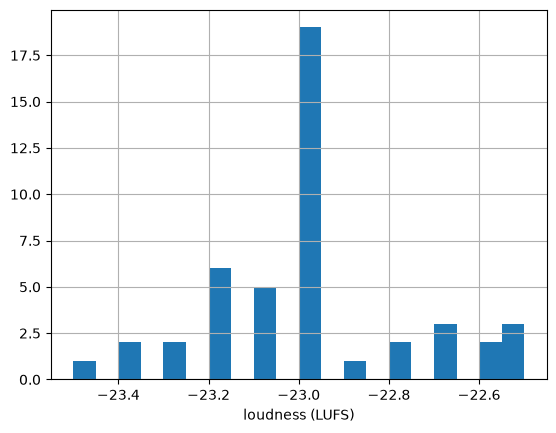

In [6]:
# %% 0. Read-only check: specs and loudness of every clip, straight from the files
#      Changes nothing. Run it at any time to confirm that all clips are technically uniform.
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from src.media import read_specs, measure_loudness

VIDEO_DIR = Path("videos")          # the 46 normalized clips, named <source>_<nn>.mp4
CSV_PATH  = Path("videos.csv")      # one row per clip: id, source, duration, loudness, ...

# One row per clip, measured from the file itself (not copied from videos.csv)
video_ids = pd.read_csv(CSV_PATH, encoding="utf-8-sig")["video_id"]
specs = pd.DataFrame([{"video_id": vid,
                       **read_specs(VIDEO_DIR / f"{vid}.mp4"),
                       "loudness": measure_loudness(VIDEO_DIR / f"{vid}.mp4")}
                      for vid in video_ids])

# ---- Inspect ----
spec_columns = ["width", "height", "fps", "video_codec", "pix_fmt",
                "audio_codec", "sample_rate", "channels"]
print("Spec combinations (ideally one row with all 46 clips):\n",
      specs.groupby(spec_columns, dropna=False).size(), "\n")
print("Loudness (LUFS), target -23:\n", specs["loudness"].describe().round(2), "\n")
print("Five quietest and five loudest:\n",
      pd.concat([specs.nsmallest(5, "loudness"), specs.nlargest(5, "loudness")])
        [["video_id", "duration", "loudness"]].to_string(index=False))
specs["loudness"].hist(bins=20); plt.xlabel("loudness (LUFS)"); plt.show()

## 1. Normalize the clips

Every clip is brought to 1920×1080, 25 frames per second, H.264 video and AAC stereo audio, and its loudness is shifted to −23 LUFS (EBU R128, tolerance ±0.5). Clips that already meet the targets are left alone, so the step can be rerun safely. The clips on disk are already normalized, so the step is switched off (`NORMALIZE = False` in 1a); cell 1b then only shows the clips as recorded in `videos.csv`.

Why: the clips come from different broadcasters. Uniform technical properties mean that no clip stands out for a technical reason and that clips can be joined without further processing.

In [7]:
# %% 1a. Normalize: settings
from pathlib import Path
import pandas as pd
from src.media import read_specs, measure_loudness, reformat_clip, level_loudness

# The clips on disk are already normalized. Set to True only to check and fix them again (e.g. after
# adding or replacing clips); with False, 1b only shows the clips as recorded in videos.csv.
NORMALIZE          = False

VIDEO_DIR          = Path("videos")
CSV_PATH           = Path("videos.csv")
# Every clip must have exactly these properties, so that clips can be joined without re-scaling
# and no clip stands out technically.
TARGET_SPECS       = {"width": 1920, "height": 1080, "fps": "25/1",
                      "video_codec": "h264", "pix_fmt": "yuv420p",
                      "audio_codec": "aac", "sample_rate": "48000", "channels": 2}
TARGET_LUFS        = -23.0     # EBU R128
LOUDNESS_TOLERANCE = 0.5       # allowed distance from the target, in LUFS
SILENCE_LUFS       = -60.0     # below this a clip counts as silent and is not levelled

In [8]:
# %% 1b. Normalize: check every clip, fix what is off, refresh videos.csv
#      Does the work only when NORMALIZE is True (1a). Only clips that deviate from the targets are
#      touched, so a second run changes nothing.
videos = pd.read_csv(CSV_PATH, encoding="utf-8-sig")

if not NORMALIZE:
    print("Skipped: the clips are already normalized (NORMALIZE = False in 1a).")
else:
    # The folder and the CSV must list exactly the same clips before anything is changed.
    on_disk = {p.stem for p in VIDEO_DIR.glob("*.mp4")}
    in_csv  = set(videos["video_id"])
    assert on_disk == in_csv, (
        f"Folder and CSV disagree. Only in folder: {sorted(on_disk - in_csv)}. "
        f"Only in CSV: {sorted(in_csv - on_disk)}.")

    reformatted, levelled = [], []
    for vid in videos["video_id"]:
        path  = VIDEO_DIR / f"{vid}.mp4"
        specs = read_specs(path)

        # 1. Picture and audio format: re-encode only if any property differs from the target.
        if any(specs[key] != target for key, target in TARGET_SPECS.items()):
            reformat_clip(path, has_audio=specs["audio_codec"] is not None, target_specs=TARGET_SPECS)
            reformatted.append(vid)

        # 2. Loudness: shift the volume if the clip is audible and outside the tolerance,
        #    then measure again so the CSV holds the value that is really in the file.
        loudness = measure_loudness(path)
        if loudness > SILENCE_LUFS and abs(loudness - TARGET_LUFS) > LOUDNESS_TOLERANCE:
            level_loudness(path, loudness, TARGET_LUFS)
            levelled.append(f"{vid} (was {loudness:.1f})")
            loudness = measure_loudness(path)

        row = videos["video_id"] == vid
        videos.loc[row, "duration"] = read_specs(path)["duration"]
        videos.loc[row, "loudness"] = loudness

    videos.to_csv(CSV_PATH, index=False, encoding="utf-8-sig")
    print(f"Reformatted: {len(reformatted)}  {reformatted}")
    print(f"Loudness corrected: {len(levelled)}  {levelled}")

# ---- Inspect: the clips as recorded in videos.csv ----
print(f"\n{len(videos)} clips, {videos['duration'].sum():.0f} s total footage")
print("\nDuration (s):\n", videos["duration"].describe().round(2))
print("\nLoudness (LUFS):\n", videos["loudness"].describe().round(2))
print("\nClips per source:\n", videos["source_id"].value_counts().sort_index())

Skipped: the clips are already normalized (NORMALIZE = False in 1a).

46 clips, 395 s total footage

Duration (s):
 count    46.00
mean      8.59
std       3.52
min       2.47
25%       5.32
50%       9.10
75%      11.38
max      15.30
Name: duration, dtype: float64

Loudness (LUFS):
 count    46.00
mean    -23.00
std       0.23
min     -23.50
25%     -23.10
50%     -23.00
75%     -23.00
max     -22.50
Name: loudness, dtype: float64

Clips per source:
 source_id
bbc_calais              3
democracynow_journey    5
france24_lesbos         3
france24_nl             4
ind_keten               4
nieuwsuur_denhaag       5
nieuwsuur_woede         3
nos_kroatie             3
nosop3_grenzen          6
nosop3_opvang           5
sky_mediterranean       5
Name: count, dtype: int64


## 2. Find the shots

A clip often contains several shots. This step finds the cuts by looking for abrupt changes between frames, drops detections that are less than half a second apart or right at the edge of a clip, and stores the number of shots per clip.

Why: the unit of the content analysis is the shot, and the length of the shortest shot (1.38 s) decides how densely the clips are sampled in step 3.

In [9]:
# %% 2a. Shots: settings (also needed for the picture check in 5d)
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from src.media import find_cuts, shot_intervals

VIDEO_DIR        = Path("videos")
CSV_PATH         = Path("videos.csv")
SCENE_THRESHOLD  = 0.3     # how big a frame-to-frame change counts as a cut (0-1)
MIN_SHOT_SECONDS = 0.5     # detected cuts closer together than this are treated as false
MANUAL_CUTS      = {}      # video_id: [true cut times in seconds], overrides detection for that clip

Clips with dropped detections (check these by eye):
  democracynow_journey_01: at [3.32, 3.52] s
  democracynow_journey_02: at [2.72, 3.12, 3.32, 3.52] s
  democracynow_journey_05: at [1.4, 1.6, 1.8] s

108 shots in 46 clips

Shots per clip:
 n_shots
1    14
2    13
3    11
4     6
5     1
6     1
Name: count, dtype: int64

Shot length (s):
 count    108.00
mean       3.66
std        1.91
min        1.38
25%        2.39
50%        3.04
75%        4.48
max       11.00
Name: length, dtype: float64

The 5 shortest shots:
           video_id  shot  start  end  length
nieuwsuur_woede_02     4   7.92 9.30    1.38
 nosop3_grenzen_05     2   1.92 3.32    1.40
 nosop3_grenzen_03     1   0.00 1.52    1.52
 nosop3_grenzen_03     2   1.52 3.10    1.58
 nosop3_grenzen_06     3   4.60 6.30    1.70

Shortest shot: 1.38 s  ->  at least 1.4 frames per second are needed to see every shot twice


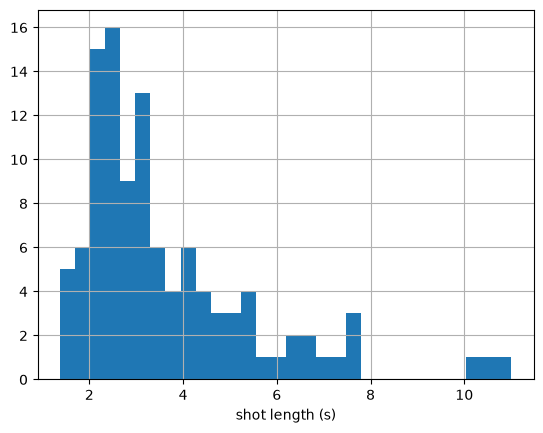

In [10]:
# %% 2b. Shots: detect cuts in every clip, write shot counts to videos.csv (safe to rerun)
videos = pd.read_csv(CSV_PATH, encoding="utf-8-sig")

rows, doubtful = [], {}
for v in videos.itertuples():
    cuts, dropped = find_cuts(v.video_id, v.duration, VIDEO_DIR, SCENE_THRESHOLD, MIN_SHOT_SECONDS, MANUAL_CUTS)
    if dropped:
        doubtful[v.video_id] = dropped                 # reported below, to be checked by eye
    for i, (start, end) in enumerate(shot_intervals(cuts, v.duration), start=1):
        rows.append({"video_id": v.video_id, "shot": i,
                     "start": round(start, 2), "end": round(end, 2),
                     "length": round(end - start, 2)})
shots = pd.DataFrame(rows)        # note: step 4 reuses the name `shots` for the described shots

# Per clip: number of shots and length of its shortest shot. Old columns are dropped first,
# so rerunning does not create duplicates.
per_clip = shots.groupby("video_id")["length"].agg(n_shots="count", shortest_shot="min")
videos = (videos.drop(columns=["n_shots", "shortest_shot"], errors="ignore")
                .merge(per_clip, left_on="video_id", right_index=True))
videos.to_csv(CSV_PATH, index=False, encoding="utf-8-sig")

# ---- Inspect ----
print("Clips with dropped detections (check these by eye):")
for vid, times in doubtful.items():
    print(f"  {vid}: at {times} s")

# The shortest shot decides how densely the clips must be sampled for the description step.
shortest = shots["length"].min()
print(f"\n{len(shots)} shots in {len(videos)} clips")
print("\nShots per clip:\n", videos["n_shots"].value_counts().sort_index())
print("\nShot length (s):\n", shots["length"].describe().round(2))
print("\nThe 5 shortest shots:\n", shots.nsmallest(5, "length").to_string(index=False))
print(f"\nShortest shot: {shortest:.2f} s  ->  at least {2 / shortest:.1f} frames per second "
      "are needed to see every shot twice")

shots["length"].hist(bins=30); plt.xlabel("shot length (s)"); plt.show()

## 3. Describe every clip

Each clip is sent to Gemini without sound, sampled at 3 frames per second. The model returns a fixed set of fields, among them one description per shot. The prompt (in `src/describe.py`) asks for what is visible only: no interpretation, no labels such as "migrant" or "refugee", no guesses about origin or religion.

The descriptions are stored in `results/video_descriptions.csv` and are the fixed data for everything that follows. The step is switched off (`DESCRIBE = False` in 3a), so running the notebook never calls Gemini or asks for a key; cell 3b then only shows the stored descriptions.

Why: the descriptions are the data for steps 4 to 6. Describing only what is on screen keeps the later content types about what is shown, and not about how a broadcast frames it.

In [11]:
# %% 3a. Describe: settings (the prompt and the structure of the answer are in src/describe.py)
from pathlib import Path
import pandas as pd

VIDEO_DIR     = Path("videos")
CSV_PATH      = Path("videos.csv")
DESC_PATH     = Path("results/video_descriptions.csv")
DESC_PATH.parent.mkdir(exist_ok=True)      # every generated file goes into results/
MODEL         = "gemini-3.5-flash-lite"
SAMPLE_FPS    = 3          # shortest shot is 1.38 s, so every shot is seen at least four times
PAUSE_SECONDS = 5          # stays under 15 requests per minute
# Every clip is described already, and Gemini never gives the same wording twice, so the stored
# descriptions are the data. Set to True only to describe clips that are not in DESC_PATH yet.
DESCRIBE      = False

In [12]:
# %% 3b. Describe: run Gemini on every clip not yet described (needs a Gemini API key)
#      Does the work only when DESCRIBE is True (3a). The descriptions already in video_descriptions.csv
#      are the data for everything that follows; Gemini does not give the same wording twice, so keep
#      that file: do not delete and regenerate it.
video_ids = pd.read_csv(CSV_PATH, encoding="utf-8-sig")["video_id"]

if not DESCRIBE:
    print("Skipped: the stored descriptions are used (DESCRIBE = False in 3a).")
else:
    from getpass import getpass
    import time
    from google import genai
    from src.describe import describe_clip

    client = genai.Client(api_key=getpass("Gemini API key: "))
    rows = pd.read_csv(DESC_PATH, encoding="utf-8-sig").to_dict("records") if DESC_PATH.exists() else []
    described = {r["video_id"] for r in rows}

    for vid in video_ids:
        if vid in described:               # already done in an earlier run: skip
            continue
        rows.append({"video_id": vid, "model": MODEL, "sample_fps": SAMPLE_FPS,
                     **describe_clip(client, vid, VIDEO_DIR, MODEL, SAMPLE_FPS)})
        pd.DataFrame(rows).to_csv(DESC_PATH, index=False, encoding="utf-8-sig")   # save after every clip
        print("done:", vid)
        time.sleep(PAUSE_SECONDS)

# ---- Inspect: the stored descriptions ----
descriptions = pd.read_csv(DESC_PATH, encoding="utf-8-sig")
print(f"\n{len(descriptions)} of {len(video_ids)} clips described\n")
for r in descriptions.itertuples():
    print(f"{r.video_id}  ({r.n_shots_described} shots)\n  {r.summary}\n")

Skipped: the stored descriptions are used (DESCRIBE = False in 3a).

46 of 46 clips described

nieuwsuur_denhaag_01  (1 shots)
  A medium shot captures a shirtless man pushing a bicycle laden with boxes along a city sidewalk, accompanied by a young girl in a pink dress, past various shops and parked cars.

nieuwsuur_denhaag_02  (2 shots)
  A clip showing several men walking past a playground and hanging out near a brick wall outdoors. The first shot captures individuals walking on a sidewalk, while the second shot reveals a larger group of men gathered near a brick wall.

nieuwsuur_denhaag_03  (3 shots)
  A group of men gather on a city street during the daytime, talking and walking together past parked cars and trees.

nieuwsuur_denhaag_04  (3 shots)
  This video clip shows a series of street scenes at night. It starts with two people standing in front of a lit storefront, followed by a person standing on a sidewalk watching traffic, and ends with a woman holding a paper cup next to p

## 4. The content space

Every shot description is turned into a vector by a sentence-embedding model, after camera vocabulary ("wide shot", "close-up") has been removed, so that shots are compared on content and not on framing. A principal component analysis then finds the main directions along which the shots differ.

**How many dimensions?** Parallel analysis: a dimension is kept if it is stronger than the same dimension in scrambled data, in 95% of 1,000 scrambles.

**Checks in 4b**
- a second text model should place the shots at similar distances from each other;
- distances in the retained dimensions should agree with distances in the full space;
- the shots that the retained dimensions capture least are listed: these are the one-off shots.

The two pictures (heatmap and map) are for orientation only. No later step uses them.

In [13]:
# %% 4a. Content space: settings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import MDS
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.spatial.distance import pdist, squareform
from src.content import load_shots, embed, count_real_dimensions

DESC_PATH      = Path("results/video_descriptions.csv")
DESC_PATH.parent.mkdir(exist_ok=True)      # every generated file goes into results/
EMBED_MODEL    = "all-mpnet-base-v2"
CHECK_MODEL    = "all-MiniLM-L6-v2"     # second text model, only used to check robustness
N_SCRAMBLES    = 1000                   # scrambled versions of the data in the parallel analysis
NOISE_QUANTILE = 95                     # a dimension must beat this percentage of scrambled versions

/opt/homebrew/Caskroom/miniconda/base/envs/migration-stimuli/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 6219.90it/s]


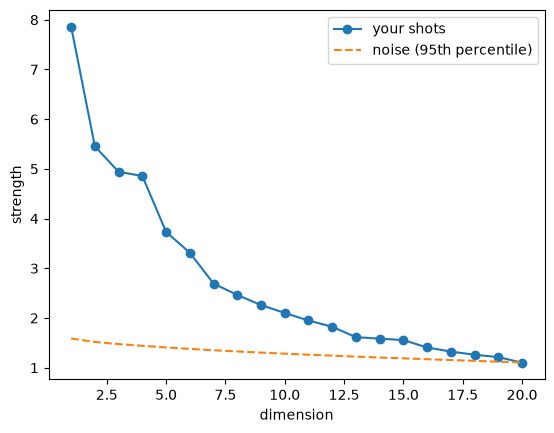

112 shots; 19 dimensions are stronger than noise and hold 64% of the variation



Loading weights: 100%|██████████| 103/103 [00:00<00:00, 7951.80it/s]


Shot distances agree between the two text models at 0.88
Distances in the 19 retained dimensions agree with the full space at 0.92
Shots least captured by the retained dimensions (the most individual ones):
   42%  democracynow_journey_03  Medium shot panning horizontally across the tinted windows of a parked bus, show
   43%  democracynow_journey_02  A low-angle medium shot shows children and women walking in single file along a 
   44%  france24_lesbos_03       A medium shot shows a group of women and children washing clothes and items on t
   45%  nosop3_grenzen_01        A high-angle, elevated medium shot shows a small black inflatable raft drifting 
   48%  nosop3_opvang_01         Medium-wide shot of an outdoor tarmac area with a large crowd of people walking 
   48%  nieuwsuur_denhaag_02     Medium shot showing a group of men sitting and standing near a low brick wall in
   50%  nosop3_opvang_03         Close-up shot of the lower bodies of multiple people walking along a path, c

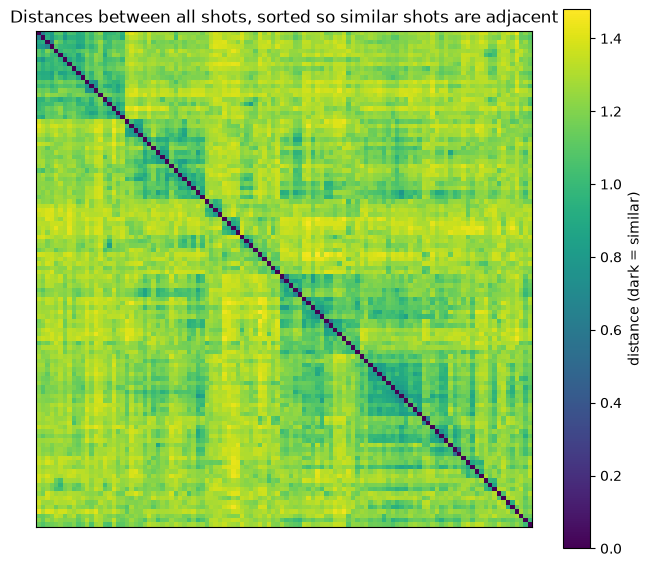

/opt/homebrew/Caskroom/miniconda/base/envs/migration-stimuli/lib/python3.12/site-packages/sklearn/manifold/_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(


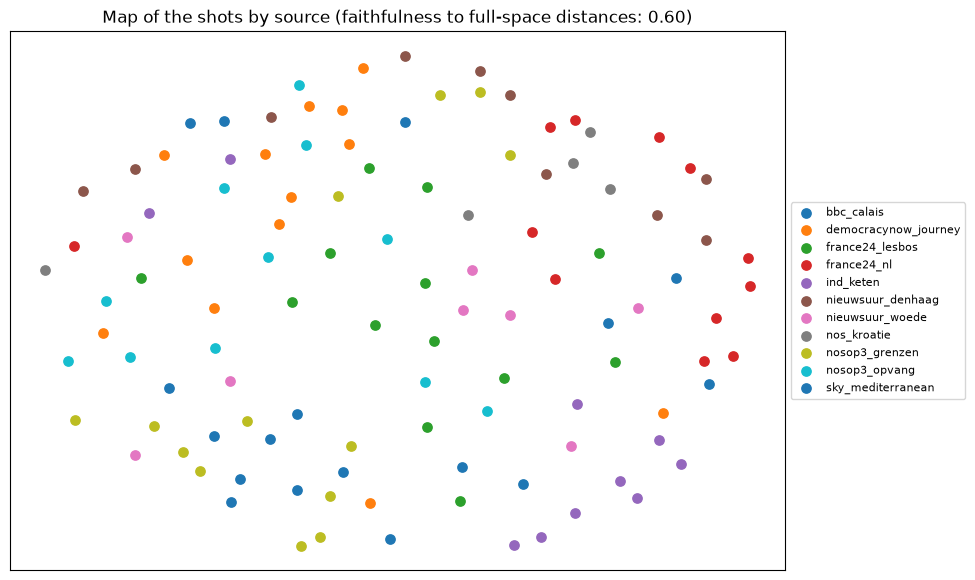

In [14]:
# %% 4b. Content space: embed the shots, keep the dimensions that beat noise, check and picture the space
shots      = load_shots(DESC_PATH)              # one row per described shot, camera words removed
embeddings = embed(shots, EMBED_MODEL)          # the full space; step 7 measures coverage in this

# ---- How many dimensions are stronger than noise? ----
n_dims, strength, limit = count_real_dimensions(embeddings, np.random.default_rng(0), N_SCRAMBLES, NOISE_QUANTILE)
plt.plot(range(1, 21), strength[:20], "o-", label="your shots")
plt.plot(range(1, 21), limit[:20], "--", label=f"noise ({NOISE_QUANTILE}th percentile)")
plt.xlabel("dimension"); plt.ylabel("strength"); plt.legend(); plt.show()
# `scores`: every shot's position on the retained dimensions (shots x n_dims).
# svd_solver="full" makes the PCA exact, so the result is identical on every run.
scores = PCA(n_components=n_dims, svd_solver="full").fit_transform(embeddings)
print(f"{len(shots)} shots; {n_dims} dimensions are stronger than noise and hold "
      f"{(strength[:n_dims].sum() / strength.sum()):.0%} of the variation\n")

# ---- Checks ----
centered = embeddings - embeddings.mean(axis=0)
# 1. Does a different text model place the shots at similar distances from each other?
print(f"Shot distances agree between the two text models at "
      f"{np.corrcoef(pdist(embeddings), pdist(embed(shots, CHECK_MODEL)))[0, 1]:.2f}")
# 2. How much of the distance structure survives when only the retained dimensions are used?
print(f"Distances in the {n_dims} retained dimensions agree with the full space at "
      f"{np.corrcoef(pdist(scores), pdist(embeddings))[0, 1]:.2f}")
# 3. Per shot: the share of its distance from the average shot that the retained dimensions hold.
#    A low share marks a one-off shot, whose content lies mostly outside the common dimensions.
shots["captured"] = (scores ** 2).sum(axis=1) / (centered ** 2).sum(axis=1)
print("Shots least captured by the retained dimensions (the most individual ones):")
for r in shots.nsmallest(8, "captured").itertuples():
    print(f"   {r.captured:.0%}  {r.video_id:<24} {r.description[:80]}")

# ---- Pictures ----
# Heatmap of all shot-to-shot distances; the shots are sorted by a clustering tree only to
# put similar shots next to each other. The tree is not used for anything else.
order = leaves_list(linkage(embeddings, "ward"))
plt.figure(figsize=(8, 7))
plt.imshow(squareform(pdist(embeddings))[np.ix_(order, order)], cmap="viridis")
plt.colorbar(label="distance (dark = similar)")
plt.title("Distances between all shots, sorted so similar shots are adjacent")
plt.xticks([]); plt.yticks([]); plt.show()

# Flat map of the shots (MDS): an impression only. The title reports how faithfully the flat
# distances reproduce the real ones; no analysis uses these coordinates.
xy = MDS(n_components=2, random_state=0).fit_transform(embeddings)
plt.figure(figsize=(10, 7))
for source, group in shots.groupby("source_id"):
    plt.scatter(xy[group.index, 0], xy[group.index, 1], s=45, label=source)
plt.legend(fontsize=8, loc="center left", bbox_to_anchor=(1, 0.5))
plt.title(f"Map of the shots by source (faithfulness to full-space distances: "
          f"{np.corrcoef(pdist(xy), pdist(embeddings))[0, 1]:.2f})")
plt.xticks([]); plt.yticks([]); plt.show()

## 5. The dimensions

The retained dimensions are rotated, so that each one separates a small number of shots clearly from the rest and can be read as a contrast in content. Three questions are then answered.

1. **Which rotation?** Oblimin is fitted first. If no two of its dimensions correlate at 0.32 or more, the uncorrelated varimax solution is used. Cell 5b-check shows whether the choice makes a practical difference.
2. **Which dimensions are stable?** The whole analysis is redone on random subsets of 80% of the shots. A dimension is kept if it matches its counterpart in those refits at 0.75 or better on average.
3. **Are they visible in the footage?** (5c and 5d) An image model that never sees the descriptions is used to predict each dimension from the frames, always for a broadcast it was not trained on. A dimension that can be predicted this way reflects content that is in the pictures.

Each stable dimension is printed with the words and example shots of its two sides. The dimension numbers printed there are the ones step 6 refers to.

In [15]:
# %% 5a. Dimensions: settings
from src.content import rotate, oblimin_correlations, dimension_stability, typical_words

DIMS_PATH    = Path("results/shot_dimensions.csv")
N_RESAMPLES  = 1000       # refits on subsets; used for the stability of the dimensions (5b) and of the tags (6b)
SUBSAMPLE    = 0.8        # share of shots in each refit
STABLE_AT    = 0.75       # a rotated dimension is kept if it matches its refits at least this well on average
OBLIQUE_FROM = 0.32       # use oblimin if any two rotated dimensions correlate at least this much
N_EXAMPLES   = 3          # example shots printed per side of a dimension

In [16]:
# %% 5b. Dimensions: rotate the retained components, keep the stable ones, interpret them (run 4b first)

# ---- Rotation: varimax or oblimin, by rule ----
# Oblimin is fitted first, only to see how strongly its dimensions correlate. If no pair reaches
# the threshold, the simpler uncorrelated solution is used.
phi      = oblimin_correlations(scores)
largest  = np.abs(phi - np.eye(n_dims)).max()
ROTATION = "oblimin" if largest >= OBLIQUE_FROM else "varimax"
print(f"Largest correlation between oblimin dimensions: {largest:.2f}  ->  using {ROTATION.upper()} "
      f"(rule: oblimin from {OBLIQUE_FROM})\n")
rotated_all = rotate(scores, ROTATION)          # shots x n_dims; column d is rotated dimension d + 1

# ---- Stability: does each rotated dimension come back when the analysis is redone on subsets? ----
# Each refit redoes PCA and rotation on a random 80% of the shots and is compared with the
# full analysis on those same shots.
dim_stability = dimension_stability(embeddings, rotated_all, ROTATION, np.random.default_rng(0),
                                    N_RESAMPLES, SUBSAMPLE)     # average match per dimension, 0 to 1
keep          = np.where(dim_stability >= STABLE_AT)[0]         # 0-based positions of the stable dimensions
print(f"Stability of the {n_dims} rotated dimensions, best first:")
print("  ", "  ".join(f"{s:.2f}" for s in sorted(dim_stability, reverse=True)))
print(f"\n{len(keep)} dimensions are stable at {STABLE_AT} or higher\n")

# ---- Interpretation: what each stable dimension runs between ----
# Dimensions are printed with 1-based numbers (d + 1); those numbers are the ones used in step 6.
for d in keep:
    high, low = typical_words(shots, rotated_all[:, d])
    column    = pd.Series(rotated_all[:, d])
    print(f"DIMENSION {d + 1}  (stability {dim_stability[d]:.2f})")
    print(f"  high side: {high}")
    for i in column.nlargest(N_EXAMPLES).index:
        print(f"      + {shots.loc[i, 'description'][:100]}")
    print(f"  low side:  {low}")
    for i in column.nsmallest(N_EXAMPLES).index:
        print(f"      - {shots.loc[i, 'description'][:100]}")
    print()

for d in keep:
    shots[f"dim_{d + 1}"] = rotated_all[:, d]
shots.to_csv(DIMS_PATH, index=False, encoding="utf-8-sig")

Largest correlation between oblimin dimensions: 0.23  ->  using VARIMAX (rule: oblimin from 0.32)

Stability of the 19 rotated dimensions, best first:
   0.98  0.97  0.95  0.95  0.95  0.93  0.91  0.87  0.86  0.86  0.85  0.82  0.81  0.81  0.80  0.78  0.70  0.66  0.62

16 dimensions are stable at 0.75 or higher

DIMENSION 1  (stability 0.98)
  high side: paved, bushes, child, buildings, backpacks, roadside
      + A medium tracking shot shows several individuals walking along a paved road, carrying luggage and pe
      + A close shot shows several people with large backpacks and bags walking along a paved area near a si
      + Medium shot of people walking along a paved path in daylight, partially obscured by figures in the f
  low side:  triton, vos, ship, labeled, cargo, deck
      - High aerial view of a small grey military-style vessel docked alongside a larger red and white ship 
      - Slightly wider aerial view of the red and white 'VOS TRITON' ship on the blue ocean, with small

In [17]:
# %% 5b-check. Does it matter whether the retained dimensions are rotated with varimax or oblimin? (run 5b first)
#      A check only: nothing downstream uses its results.
oblimin_all = rotate(scores, "oblimin")
overlap     = phi[np.triu_indices(n_dims, 1)]                   # every pair of oblimin dimensions once
print(f"Correlations between oblimin dimensions: {len(overlap)} pairs, largest {np.abs(overlap).max():.2f}")
print(f"   pairs above 0.2: {(np.abs(overlap) > 0.2).sum()};  above 0.3: {(np.abs(overlap) > 0.3).sum()};  "
      f"typical size (median): {np.median(np.abs(overlap)):.2f}\n")

# For each varimax dimension: its correlation with the oblimin dimension that resembles it most.
corr  = np.abs(np.corrcoef(rotated_all.T, oblimin_all.T)[:n_dims, n_dims:])
match = corr.max(axis=1)
print("Agreement of each varimax dimension with its closest oblimin dimension (1 = identical):")
for d in range(n_dims):
    print(f"   dim {d + 1:2d}: {match[d]:.2f}{'' if d in keep else '   (not stable, not used)'}")
print(f"\nLowest agreement among the stable dimensions: {match[keep].min():.2f}")

Correlations between oblimin dimensions: 171 pairs, largest 0.23
   pairs above 0.2: 1;  above 0.3: 0;  typical size (median): 0.04

Agreement of each varimax dimension with its closest oblimin dimension (1 = identical):
   dim  1: 0.97
   dim  2: 0.98
   dim  3: 0.88
   dim  4: 0.97
   dim  5: 0.98
   dim  6: 0.99
   dim  7: 0.99
   dim  8: 0.99
   dim  9: 0.98
   dim 10: 0.99
   dim 11: 0.99
   dim 12: 0.99
   dim 13: 0.98
   dim 14: 0.96   (not stable, not used)
   dim 15: 0.99
   dim 16: 0.99
   dim 17: 0.99   (not stable, not used)
   dim 18: 0.92   (not stable, not used)
   dim 19: 0.97

Lowest agreement among the stable dimensions: 0.88


In [18]:
# %% 5c. Dimensions, picture check: settings (uses the shot settings from 2a)
from sentence_transformers import SentenceTransformer
from src.pictures import shot_picture_vectors, predicted_from_pictures

CSV_PATH       = Path("videos.csv")
VIDEO_DIR      = Path("videos")
DIM_TABLE_PATH = Path("results/dimensions.csv")
CLIP_MODEL     = "clip-ViT-B-16"      # image model; it never sees the descriptions
FRAME_FPS      = 3                    # frames sampled per second, as in the description step

In [19]:
# %% 5d. Dimensions, picture check: do the space and the dimensions show up in the pictures?
#      (run 2a, 4b and 5b first)
videos     = pd.read_csv(CSV_PATH, encoding="utf-8-sig")
clip_model = SentenceTransformer(CLIP_MODEL)

# ---- One picture vector per shot: the average of the frames that fall inside the shot ----
# A clip is skipped when the cut detection and the description disagree on its number of shots.
visual, skipped = shot_picture_vectors(shots, videos, clip_model, VIDEO_DIR, FRAME_FPS,
                                       SCENE_THRESHOLD, MIN_SHOT_SECONDS, MANUAL_CUTS)

seen     = np.array(sorted(visual))                  # rows of `shots` that have a picture vector
picture  = np.stack([visual[i] for i in seen])       # matched shots x picture dimensions
source_v = shots["source_id"].to_numpy()[seen]
first, second = np.triu_indices(len(seen), 1)        # same pair order as pdist
cross    = source_v[first] != source_v[second]       # pairs of shots from two different broadcasts
print(f"{len(seen)} of {len(shots)} shots matched to pictures; left out: {skipped}\n")

# ---- The space ----
# Are shots with similar descriptions also similar in the pictures? The second figure uses only
# pairs from different broadcasts, where a shared house style cannot produce the agreement.
print("Relation between text distance and picture distance (all pairs / pairs from different sources):")
for name, points in [("full description space", embeddings[seen]), (f"{n_dims} retained dimensions", scores[seen])]:
    d_text, d_pic = pdist(points), pdist(picture)
    print(f"   {np.corrcoef(d_text, d_pic)[0, 1]:.2f} / {np.corrcoef(d_text[cross], d_pic[cross])[0, 1]:.2f}   {name}")

# ---- The dimensions ----
# "visible": how well each stable dimension is predicted from pictures of unseen broadcasts.
table = []
for d in keep:
    high, low = typical_words(shots, rotated_all[:, d], n_words=4)
    table.append({"dimension": d + 1, "stability": round(dim_stability[d], 2),
                  "visible": round(predicted_from_pictures(rotated_all[seen, d], picture, source_v), 2),
                  "high_side": high, "low_side": low})
dimensions = pd.DataFrame(table).sort_values("visible", ascending=False)
dimensions.to_csv(DIM_TABLE_PATH, index=False, encoding="utf-8-sig")
print("\nStable dimensions: stability, and how well each is predicted from pictures of unseen broadcasts:\n")
print(dimensions.to_string(index=False))

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 6961.94it/s]


101 of 112 shots matched to pictures; left out: ['nieuwsuur_denhaag_02', 'nieuwsuur_denhaag_03', 'democracynow_journey_02', 'democracynow_journey_05']

Relation between text distance and picture distance (all pairs / pairs from different sources):
   0.54 / 0.48   full description space
   0.48 / 0.42   19 retained dimensions

Stable dimensions: stability, and how well each is predicted from pictures of unseen broadcasts:

 dimension  stability  visible                             high_side                            low_side
         2       0.95     0.85          cart, luggage, backpack, day     inflatable, boat, closely, life
         1       0.98     0.78       paved, bushes, child, buildings          triton, vos, ship, labeled
        12       0.95     0.61        beard, hooded, middle, looking     roadside, aid, handing, luggage
         8       0.86     0.59           drive, lane, truck, highway  gloves, headscarf, partially, deck
        11       0.93     0.58         bushes, b

## 6. Content types: what occurs in each clip

This step turns the dimensions into a table of clips by content types, filled with ones and zeros.

- **Profile.** For every clip and every stable dimension: the value of the clip's most extreme shot, in standard deviations.
- **Tag.** A clip gets a tag for one side of a dimension if it lies at least 2 standard deviations out on that side.
- **Test.** The analysis is redone on subsets, and a tag counts as confirmed only if the clip has it in more than half of the refits. Tags that only just pass the line drop out here.
- **Content type.** A side of a dimension is a content type if at least two clips carry a confirmed tag.

**Manual decisions.** The test judges whether a tag is stable, not whether a type is meaningful. Four settings in cell 6a hold the decisions made by hand: sides to exclude, the name of each type, types to add, and single cells to correct. Cell 6b prints how many decisions were made, for reporting.

The clip-level entries in `ADDED` and `CORRECTIONS` were proposed from the descriptions and checked against the footage.

In [20]:
# %% 6a. Content types: settings and your decisions
from src.content_types import standardize, clip_extremes, clip_sides, tag_shares

PROFILE_PATH   = Path("results/clip_profiles.csv")
TYPES_PATH     = Path("results/clip_types.csv")
STRONG         = 2.0      # a clip shows a side of a dimension from this many standard deviations
MAJORITY       = 0.50     # a tag is confirmed if the clip has it in more than this share of the refits
MIN_TYPE_CLIPS = 2        # a side is a content type if at least this many clips have a confirmed tag

# ---- Your decisions, applied after the test (dimension number, side) ----
# These four settings are the only manual input in the analysis. The dimension numbers are the
# ones printed in 5b. If anything upstream changes (descriptions, number of dimensions), the
# numbering can shift: read the first table that 6b prints and check that each name still
# stands next to the right words.
EXCLUDE = [(19, "high")]                  # stable but not a recognisable kind of content
NAMES   = {(8, "high"):  "Highway and trucks",      (10, "high"): "Police and checkpoints",
           (2, "low"):   "Inflatable boats",        (1, "low"):   "Ships",
           (6, "low"):   "Lines of men standing",   (11, "low"):  "Lying down, resting",
           (12, "high"): "Close-up of a face",      (3, "low"):   "Halls with cots",
           (4, "low"):   "Men sitting on grass",    (16, "low"):  "Dense crowd",
           (7, "high"):  "Aid being handed out",    (13, "low"):  "City street",
           (5, "low"):   "Classroom",               (9, "high"):  "Tent camp"}
# A content type that no single side of a dimension captures, with the clips that show it:
ADDED   = {"Walking with luggage": ["democracynow_journey_02", "nosop3_opvang_05", "nosop3_grenzen_02",
                                    "ind_keten_01"]}
# Single cells of the table set by hand: (clip, content type, 1 = occurs / 0 = does not)
CORRECTIONS = [("nieuwsuur_woede_01",      "Tent camp",          1),
               ("democracynow_journey_04", "Highway and trucks", 1),
               ("nieuwsuur_denhaag_05",    "City street",        1)]

In [21]:
# %% 6b. Content types: what occurs in each clip, yes or no (run 5b, 5d and 6a first)
#      Uses N_RESAMPLES and SUBSAMPLE from 5a. Writes clip_profiles.csv and clip_types.csv.

# Every stable dimension has two sides. The sides are listed as: all high sides, then all low sides.
clip_names    = shots["video_id"].unique()
video_of_shot = shots["video_id"].to_numpy()
side_words = {d: typical_words(shots, rotated_all[:, d], n_words=4) for d in keep}      # (high side, low side)
side_id    = [(d + 1, "high") for d in keep] + [(d + 1, "low") for d in keep]
type_label = np.array([side_words[d][0] for d in keep] + [side_words[d][1] for d in keep])

# ---- Profile from the full analysis ----
z          = standardize(rotated_all[:, keep])            # 0 = the average shot, 1 = one standard deviation
clip_z     = clip_extremes(z, video_of_shot, clip_names)  # clips x stable dimensions: the most extreme shot, signed
both_sides = clip_sides(z, video_of_shot, clip_names)    # clips x sides, 0 or positive, each side measured separately; reused in step 7
first_look = both_sides >= STRONG                         # the tags from the full analysis alone

profiles = pd.DataFrame(clip_z, index=clip_names, columns=[f"dim_{d + 1}" for d in keep]).round(2)
profiles.index.name = "video_id"
profiles.to_csv(PROFILE_PATH, encoding="utf-8-sig")

# ---- Test every tag: in what share of the refits does the clip have it? ----
# The whole route to a tag is repeated on random subsets of the shots. A tag that only just
# passes the line in the full analysis fails in many refits and is dropped.
share  = tag_shares(embeddings, rotated_all, keep, ROTATION, video_of_shot, clip_names, STRONG,
                    np.random.default_rng(0), N_RESAMPLES, SUBSAMPLE)      # clips x sides, 0 to 1
occurs = share > MAJORITY                                 # the confirmed tags

# A side becomes a content type if enough clips carry a confirmed tag and it is not excluded by hand.
candidate = occurs.sum(axis=0) >= MIN_TYPE_CLIPS
is_type   = candidate & ~np.array([s in EXCLUDE for s in side_id])
seen_in_pictures = dimensions.set_index("dimension")["visible"]       # from 5d, shown for reference only

print(f"Content types with at least {MIN_TYPE_CLIPS} confirmed tags "
      f"(a tag is confirmed if the clip has it in more than {MAJORITY:.0%} of refits):\n")
print("  dimension   confirmed  dropped as   visible in  typical words                           name")
print("              tags       borderline   pictures")
# Listed: every side that is a candidate now, or would have been one without the test.
for s in np.where(candidate | (first_look.sum(axis=0) >= MIN_TYPE_CLIPS))[0]:
    name = ("excluded by hand" if side_id[s] in EXCLUDE else
            "NOT A TYPE: too few confirmed tags" if not candidate[s] else
            NAMES.get(side_id[s], "(no name given)"))
    print(f"  dim {side_id[s][0]:2d} {side_id[s][1]:<4}  {occurs[:, s].sum():7d}  {(first_look[:, s] & ~occurs[:, s]).sum():10d}  "
          f"{seen_in_pictures[side_id[s][0]]:10.2f}   {type_label[s]:<38}  {name}")

# ---- The table: confirmed tags, then your additions and corrections ----
# `automatic` is what the analysis gives by itself; `clip_types` is the final table (clips x content
# types, 1 or 0) that step 7 selects on. The difference between the two is reported below.
automatic  = pd.DataFrame(occurs[:, is_type].astype(int), index=clip_names,
                          columns=[NAMES.get(side_id[s], type_label[s]) for s in np.where(is_type)[0]])
automatic.index.name = "video_id"
clip_types = automatic.copy()
for name, clips in ADDED.items():
    assert set(clips) <= set(clip_names), f"Unknown clip in ADDED['{name}']"
    clip_types[name] = clip_types.index.isin(clips).astype(int)
for vid, name, value in CORRECTIONS:
    if name in clip_types.columns:
        clip_types.loc[vid, name] = value
clip_types.to_csv(TYPES_PATH, encoding="utf-8-sig")

# ---- Inspect: these counts are the ones to report in the methods ----
changed = int((clip_types[automatic.columns] != automatic).to_numpy().sum())
print(f"\n{int(first_look.sum())} tags in the full analysis; {int((first_look & ~occurs).sum())} dropped as borderline, "
      f"{int((occurs & ~first_look).sum())} added because most refits show them.")
print(f"By hand: {len(EXCLUDE)} type excluded, {len(ADDED)} types added "
      f"({int(sum(len(c) for c in ADDED.values()))} tags), {changed} of {automatic.size} automatic cells corrected")

print(f"\n{clip_types.shape[1]} content types; number of clips in which each occurs:\n")
print(clip_types.sum().sort_values(ascending=False).to_string())
print("\nWhat occurs in each clip:\n")
for vid, row in clip_types.iterrows():
    print(f"{vid:<26} {' | '.join(row.index[row == 1]) if row.sum() else '(no content type)'}")

Content types with at least 2 confirmed tags (a tag is confirmed if the clip has it in more than 50% of refits):

  dimension   confirmed  dropped as   visible in  typical words                           name
              tags       borderline   pictures
  dim  7 high        3           0        0.43   handing, aid, orange, jackets           Aid being handed out
  dim  8 high        4           1        0.59   drive, lane, truck, highway             Highway and trucks
  dim  9 high        2           0        0.39   daytime, outside, makeshift, garbage    Tent camp
  dim 10 high        4           1        0.41   officer, police, passing, officers      Police and checkpoints
  dim 12 high        4           0        0.61   beard, hooded, middle, looking          Close-up of a face
  dim 19 high        2           1        0.32   wall, cargo, inside, water              excluded by hand
  dim  1 low         3           0        0.78   triton, vos, ship, labeled              Ships
  dim 

## 7. Candidate compilations

**The pool.** Every possible combination of clips is considered. A combination enters the pool if its total length is inside the window (`MIN_SECONDS` to `MAX_SECONDS`) and it shows all content types, or all but `TYPES_SLACK`.

**How all combinations can be covered.** There are 2^46 of them, about 70 trillion, too many to list. For the question "how many types, how long" it only matters which set of types a combination has and how long it is, so the combinations are counted per set and length while the clips are added one at a time (part 1 of 7b). The combinations that qualify are then listed exactly by splitting the clips into two halves and joining the halves (part 2).

**The ranking.** Within the pool, three continuous measures are put on one scale and added:
- *strength*: how clearly each content type is shown, taken from the clearest clip for that type;
- *coverage*: how fully both sides of all stable dimensions are shown;
- *gap*: how far, on average, the footage of the whole set is from the nearest selected shot in the full content space (lower is better). Every shot counts by its screen time (`SHOT_WEIGHT`), because a clip is always shown whole: counting every shot once would let a clip that cuts often weigh more than its seconds.

**Checks on the ranking.**
- *7c, representative mix*: does the content of the best compilations come in the same proportions as the whole set? Each is compared with random compilations of the same length.
- *7d, sensitivity*: the pool is ranked again with shots weighted by the square root of their length and with every shot counted once. Only the gap depends on this choice.
- *7e, robust candidates*: a compilation's robust rank is its worst rank over the three weightings, so a compilation near the top holds up whichever weighting is chosen. Near-copies are kept and shown as their difference from the best one, because one swapped clip can change what is shown.
- *7f, shorter compilations*: the pool is cut at each length in `LENGTH_LIMITS` and ranked again within each cut, to see what a shorter compilation costs.

**The output.** `results/candidate_compilations.csv` (the ten best that differ enough from each other, 7b), `results/robust_compilations.csv` (7e) and `results/length_limits.csv` (7f). A compilation here is a set of clips; the order of the clips plays no role in the selection.

In [22]:
# %% 7a. Candidates: settings
from scipy.spatial.distance import cdist
from scipy.stats import spearmanr
from src.media import shot_seconds
from src.selection import (type_strength, count_combinations, list_combinations, build_pool, pick_distinct,
                           shot_weights, content_mix, random_compilations, robust_ranking, missing_types)

CAND_PATH        = Path("results/candidate_compilations.csv")
ROBUST_PATH      = Path("results/robust_compilations.csv")
LIMITS_PATH      = Path("results/length_limits.csv")

# ---- The pool of acceptable compilations ----
MIN_SECONDS      = 50          # the pool: compilations of at least this length ...
MAX_SECONDS      = 65          # ... and at most this length ...
TYPES_SLACK      = 1           # ... that miss at most this many content types

# ---- Ranking within the pool ----
STRENGTH_CEILING = 4.0         # a clip this many standard deviations out is a perfectly clear example of a type
CEILING          = 2.0         # for coverage: reaching this far out on a side of a dimension counts as fully shown
WEIGHTS          = {"strength": 1.0, "coverage": 1.0, "gap": 1.0}     # how much each continuous measure counts
# How much a shot counts in the gap and the mix, from its screen time: "seconds" (every second counts
# equally), "sqrt" (longer counts more, with diminishing returns) or "shot" (every shot once).
SHOT_WEIGHT      = "seconds"                  # the main analysis
SENSITIVITY      = ["sqrt", "shot"]           # 7d ranks the pool again with each of these

# ---- What is printed and saved ----
N_CANDIDATES     = 10          # number of candidates to print and save (7b), and of distinct alternatives (7e)
MAX_SHARED_CLIPS = 6           # two of those candidates may share at most this many clips

# ---- Checks ----
N_MIX            = 50          # 7c: number of best compilations whose content mix is checked
N_RANDOM         = 5000        # 7c: random compilations drawn as the reference
N_COMPARE        = 50          # 7d: size of the top list compared between weightings
N_ROBUST         = 15          # 7e: number of compilations listed by robust rank, near-copies included
LENGTH_LIMITS    = [65, 64, 63, 62, 61, 60, 59, 58, 57, 56, 55]     # 7f: compare the best up to each length (s)

# ---- The overview by length (information only; it does not affect the selection) ----
OVERVIEW_FROM, OVERVIEW_TO = 30, 90      # seconds: range of the length overview
STEP             = 0.5         # seconds: clip lengths are rounded to this for the exact count
BAND             = 10          # seconds: width of the bands in the overview

In [23]:
# %% 7b. Candidates: all combinations that show (nearly) every content type, ranked on the continuous scores
#      (run 2a, 4b, 6b and 7a first; 2a for the shot lengths)
#      Every possible combination of clips is considered, not a random sample. A compilation is a
#      set of clips: the order of the clips plays no role here.
videos    = pd.read_csv(CSV_PATH, encoding="utf-8-sig")
clip_ids, durations, sources = (videos[c].to_numpy() for c in ["video_id", "duration", "source_id"])
shot_clip = shots["video_id"].map({v: i for i, v in enumerate(clip_ids)}).to_numpy()      # per shot: index of its clip
distances = cdist(embeddings, embeddings)                 # shot-to-shot distances in the full space

# Screen time of every shot, and from it the weight of every shot in the gap (SHOT_WEIGHT in 7a).
shot_secs, split_evenly = shot_seconds(shots, videos, VIDEO_DIR, SCENE_THRESHOLD, MIN_SHOT_SECONDS, MANUAL_CUTS)
shot_w    = shot_weights(shot_secs, SHOT_WEIGHT)
print(f"Shot lengths from the cut detection for {len(clip_ids) - len(split_evenly)} clips; "
      f"split evenly over the described shots for {len(split_evenly)}: {split_evenly}")
print(f"Shots weighted by: {SHOT_WEIGHT}\n")

# From here on, clips are in the order of videos.csv (clip_ids), not in the order of step 6.
final      = clip_types.loc[clip_ids]                     # the table from step 6, with your decisions applied
has_type   = final.to_numpy().astype(bool)                # clips x content types, yes or no
type_names = final.columns.to_numpy()
sides      = both_sides[pd.Index(clip_names).get_indexer(clip_ids)]      # clips x sides, continuous
n_all      = has_type.shape[1]
# One printable line per clip (name, length, content types), used in the listings of 7b to 7f.
clip_label = [f"{clip_ids[i]:<26} {durations[i]:5.1f} s  "
              f"{' | '.join(type_names[has_type[i]]) if has_type[i].any() else '(no content type)'}"
              for i in range(len(clip_ids))]

# How clearly each clip shows each type (0 to 1). The columns of the table are the types that come
# from a dimension, in the order of `is_type`, followed by the types added by hand (None).
type_sides  = list(np.where(is_type)[0]) + [None] * (n_all - int(is_type.sum()))
strength_of = type_strength(sides, has_type, type_sides, STRONG, STRENGTH_CEILING)

# ---- Part 1: exact count over ALL combinations, by length and number of content types ----
by_k = count_combinations(durations, has_type, STEP, OVERVIEW_TO)      # (number of types) x length in STEPs
print(f"All {2 ** len(clip_ids):,} combinations of {len(clip_ids)} clips; {n_all} content types.\n")
print("  seconds   combinations        most types shown   showing all types")
for start in range(OVERVIEW_FROM, OVERVIEW_TO, BAND):
    block = by_k[:, int(start / STEP):int((start + BAND) / STEP)].sum(axis=1)
    print(f"  {start:3d}-{start + BAND:<3d}   {int(block.sum()):>18,}   {np.where(block > 0)[0].max():12d}   {int(block[n_all]):>17,}")
# The most types any combination in the window shows, and the entry level for the pool.
in_window = by_k[:, int(MIN_SECONDS / STEP):int(MAX_SECONDS / STEP) + 1].sum(axis=1)
best_k    = int(np.where(in_window > 0)[0].max())
level     = best_k - TYPES_SLACK

# ---- Part 2: the pool: every combination in the window that shows at least `level` types ----
combinations = list_combinations(durations, has_type, MIN_SECONDS, MAX_SECONDS, level)
pool = build_pool(combinations, durations, sources, has_type, strength_of, sides, CEILING,
                  shot_clip, distances, shot_w, WEIGHTS)          # one row per compilation, best first

print(f"\nPool: {len(pool):,} compilations of {MIN_SECONDS}-{MAX_SECONDS} s showing at least {level} of {n_all} types")
print(pool["n_types"].value_counts().sort_index(ascending=False).rename("compilations").to_string())
print("\nRange of the continuous measures in the pool:")
for name in ("strength", "coverage", "gap"):
    print(f"  {name:<9} {pool[name].min():.3f} to {pool[name].max():.3f}")
print("\nRank of the best compilation showing each number of types:")
for k in sorted(pool["n_types"].unique(), reverse=True):
    print(f"  {k} types: best is at rank {pool.index[pool['n_types'] == k][0] + 1}")

# ---- The best that differ from each other ----
picked = pick_distinct(pool, N_CANDIDATES, MAX_SHARED_CLIPS)

pd.DataFrame([{"candidate": n, "video_ids": ";".join(clip_ids[list(p.clips)]), "seconds": round(p.seconds, 1),
               "content_types": p.n_types, "sources": p.n_sources, "score": round(p.score, 2),
               "strength": round(p.strength, 3), "coverage": round(p.coverage, 3), "gap": round(p.gap, 3)}
              for n, p in enumerate(picked, start=1)]).to_csv(CAND_PATH, index=False, encoding="utf-8-sig")

# ---- Inspect ----
print()
for n, p in enumerate(picked, start=1):
    chosen  = list(p.clips)
    clarity = strength_of[chosen].max(axis=0)             # per type: how clearly the compilation shows it
    print(f"CANDIDATE {n} (rank {p.Index + 1}): {len(chosen)} clips from {p.n_sources} sources, {p.seconds:.1f} s, "
          f"{p.n_types} of {n_all} types, shortest clip {p.shortest_clip:.1f} s")
    print(f"    score {p.score:+.2f}   strength {p.strength:.2f}   coverage {p.coverage:.0%}   gap {p.gap:.3f}")
    for i in chosen:
        print(f"    {clip_label[i]}")
    print(f"    missing: {missing_types(chosen, has_type, type_names)}")
    print("    shown least clearly: "
          + "; ".join(f"{type_names[t]} ({clarity[t]:.2f})" for t in np.argsort(clarity)[:3]))
    print(f"    least covered shot: {shots.loc[p.worst_shot, 'description'][:95]}\n")

Shot lengths from the cut detection for 42 clips; split evenly over the described shots for 4: ['nieuwsuur_denhaag_02', 'nieuwsuur_denhaag_03', 'democracynow_journey_02', 'democracynow_journey_05']
Shots weighted by: seconds

All 70,368,744,177,664 combinations of 46 clips; 14 content types.

  seconds   combinations        most types shown   showing all types
   30-40             1,732,382             10                   0
   40-50            16,241,894             12                   0
   50-60           115,118,991             13                   0
   60-70           647,952,589             14                 419
   70-80         2,994,428,520             14              22,428
   80-90        11,637,939,253             14             586,465

Pool: 2,654 compilations of 50-65 s showing at least 13 of 14 types
n_types
14      35
13    2619

Range of the continuous measures in the pool:
  strength  0.629 to 0.740
  coverage  0.775 to 0.883
  gap       0.783 to 0.834

Rank of the b

In [24]:
# %% 7c. Check: how representative is the content mix of the best compilations? (run 7b first)
#      A check only: nothing downstream uses it and nothing is saved.
#      mix:    energy distance between the compilation's footage and all footage, every shot counted by
#              its weight (SHOT_WEIGHT). A compilation whose content comes in the same proportions as the
#              whole set lands where random compilations of the same length land. Above that the content
#              is too narrow (a few kinds dominate), below it too broad (rare content over-represented).
#      spread: average distance between two moments of the compilation, relative to the whole set
#              (above 1 = more varied than the set).
random_sets = random_compilations(durations, MIN_SECONDS, MAX_SECONDS, N_RANDOM, np.random.default_rng(0))
random_mix, random_spread = np.array([content_mix(c, shot_clip, distances, shot_w) for c in random_sets]).T
center = np.median(random_mix)                           # where a representative compilation lands

top = pool.head(N_MIX).copy()
top["rank"] = top.index + 1
top["mix"], top["spread"] = np.array([content_mix(c, shot_clip, distances, shot_w) for c in top["clips"]]).T
# mix_pct: share of random compilations that lie further from the center than this one
# (100 = as typical as a random compilation, 0 = more extreme than every random one)
top["mix_pct"]   = [round(100 * (np.abs(random_mix - center) > abs(v - center)).mean()) for v in top["mix"]]
top["direction"] = np.where(top["mix"] < center, "broad", "narrow")

print(f"Random compilations of {MIN_SECONDS}-{MAX_SECONDS} s ({N_RANDOM}): mix median {center:.3f} "
      f"(middle 90%: {np.percentile(random_mix, 5):.3f} to {np.percentile(random_mix, 95):.3f}), "
      f"spread median {np.median(random_spread):.2f}\n")
print(f"The {N_MIX} best compilations (mix_pct: 100 = as representative as random sampling, "
      f"0 = less representative than any random compilation):\n")
print(top[["rank", "n_types", "seconds", "n_sources", "score", "mix", "spread", "mix_pct", "direction"]]
      .round({"seconds": 1, "score": 2, "mix": 3, "spread": 2}).to_string(index=False))
print(f"\nMedian over the {N_MIX}: mix_pct {np.median(top['mix_pct']):.0f}; "
      f"{(top['direction'] == 'broad').sum()} too broad, {(top['direction'] == 'narrow').sum()} too narrow; "
      f"median spread {np.median(top['spread']):.2f} (random: {np.median(random_spread):.2f})")
print("Most representative mix among them: rank", ", ".join(str(r) for r in top.nlargest(5, "mix_pct")["rank"]))
print(f"Correlation of mix_pct with the ranking score: {np.corrcoef(top['mix_pct'], top['score'])[0, 1]:+.2f} "
      "(positive = higher-ranked compilations also have a more representative mix)")

Random compilations of 50-65 s (5000): mix median 0.014 (middle 90%: -0.005 to 0.042), spread median 0.99

The 50 best compilations (mix_pct: 100 = as representative as random sampling, 0 = less representative than any random compilation):

 rank  n_types  seconds  n_sources  score    mix  spread  mix_pct direction
    1       13     64.5          8   5.58  0.003    1.01       40     broad
    2       13     64.0          8   5.49 -0.002    1.01       25     broad
    3       13     64.6          8   5.14  0.005    1.02       48     broad
    4       13     63.2          8   4.97  0.001    1.01       34     broad
    5       13     64.3          8   4.89 -0.005    1.02       17     broad
    6       13     64.2          7   4.89 -0.003    1.02       21     broad
    7       13     64.6          8   4.76 -0.001    1.01       26     broad
    8       13     64.1          7   4.71 -0.004    1.01       18     broad
    9       13     64.1          8   4.65  0.001    1.02       32     broad

In [25]:
# %% 7d. Check: does the ranking depend on how shots are weighted? (run 7b first)
#      The pool is ranked again with each weighting in SENSITIVITY. Only the gap depends on the
#      weighting; strength and coverage are per clip and stay the same. Nothing is saved; the
#      rankings are kept in `all_ranks` for 7e and 7f.
main_order = list(pool["clips"])                              # the pool in the order of the main analysis
all_ranks  = {SHOT_WEIGHT: {c: r for r, c in enumerate(main_order, start=1)}}
best_full  = next((r for r, n in enumerate(pool["n_types"], start=1) if n == n_all), None)
print(f"Main analysis: shots weighted by {SHOT_WEIGHT}. The pool of {len(pool):,} compilations is ranked again:\n")

for how in SENSITIVITY:
    alt = build_pool(combinations, durations, sources, has_type, strength_of, sides, CEILING,
                     shot_clip, distances, shot_weights(shot_secs, how), WEIGHTS)
    all_ranks[how] = {c: r for r, c in enumerate(alt["clips"], start=1)}
    ranks   = np.array([all_ranks[how][c] for c in main_order])         # in the order of the main ranking
    in_both = len(set(main_order[:N_COMPARE]) & set(alt["clips"][:N_COMPARE]))
    print(f"WEIGHTED BY {how.upper()}")
    print(f"  agreement of the two rankings over the whole pool (Spearman): "
          f"{spearmanr(np.arange(1, len(ranks) + 1), ranks)[0]:.2f}")
    print(f"  of the {N_COMPARE} best compilations, {in_both} are also among the {N_COMPARE} best here")
    print(f"  the best compilation here is rank {main_order.index(alt['clips'][0]) + 1} in the main analysis")
    if best_full:
        print(f"  the best compilation showing all {n_all} types: rank {best_full} in the main analysis, "
              f"{ranks[best_full - 1]} here")
    print("  the candidates of 7b, rank in the main analysis -> rank here:")
    print("    " + "   ".join(f"{n}: {p.Index + 1} -> {all_ranks[how][p.clips]}" for n, p in enumerate(picked, start=1)))
    print()

Main analysis: shots weighted by seconds. The pool of 2,654 compilations is ranked again:

WEIGHTED BY SQRT
  agreement of the two rankings over the whole pool (Spearman): 0.96
  of the 50 best compilations, 32 are also among the 50 best here
  the best compilation here is rank 12 in the main analysis
  the best compilation showing all 14 types: rank 13 in the main analysis, 20 here
  the candidates of 7b, rank in the main analysis -> rank here:
    1: 1 -> 8   2: 6 -> 4   3: 20 -> 62   4: 25 -> 74   5: 33 -> 83   6: 45 -> 15   7: 51 -> 152   8: 56 -> 181   9: 95 -> 100   10: 114 -> 220

WEIGHTED BY SHOT
  agreement of the two rankings over the whole pool (Spearman): 0.92
  of the 50 best compilations, 22 are also among the 50 best here
  the best compilation here is rank 12 in the main analysis
  the best compilation showing all 14 types: rank 13 in the main analysis, 27 here
  the candidates of 7b, rank in the main analysis -> rank here:
    1: 1 -> 29   2: 6 -> 5   3: 20 -> 114   4:

In [26]:
# %% 7e. Robust candidates: compilations that rank high whichever way shots are weighted (run 7d first)
#      The robust rank is a compilation's worst rank over the main analysis and the weightings of 7d.
#      Part 1 lists the N_ROBUST best, near-copies included, each as its difference from number 1;
#      part 2 the distinct alternatives. Writes results/robust_compilations.csv (the list of part 1).
robust = robust_ranking(pool, all_ranks)
cols   = [f"rank_{how}" for how in all_ranks]

def ranks_text(r):
    return " / ".join(str(r[c]) for c in cols)

# ---- Part 1: the best by robust rank, near-copies included ----
# Compilations that differ by a clip or two are all kept: the clip that differs can change what is shown.
best  = robust.head(N_ROBUST)
first = best.iloc[0]
best.assign(video_ids=[";".join(clip_ids[list(c)]) for c in best["clips"]],
            missing=[missing_types(c, has_type, type_names) for c in best["clips"]],
            seconds=best["seconds"].round(1))[
    ["video_ids", "seconds", "n_types", "missing", "n_sources", "worst_rank", *cols]
].rename_axis("robust_rank").rename(index=lambda i: i + 1).to_csv(ROBUST_PATH, encoding="utf-8-sig")

print(f"Ranks under each weighting ({' / '.join(all_ranks)}); the robust rank is the worst of them.\n")
print(f"THE {N_ROBUST} BEST BY ROBUST RANK, each shown as its difference from number 1\n")
for n, (_, r) in enumerate(best.iterrows(), start=1):
    print(f"{n:2d}. worst rank {r.worst_rank} (ranks {ranks_text(r)}), {r.seconds:.1f} s, {len(r.clips)} clips "
          f"from {r.n_sources} sources, missing: {missing_types(r.clips, has_type, type_names)}")
    if n == 1:
        for i in r.clips:
            print(f"       {clip_label[i]}")
    else:
        print(f"     shares {len(set(r.clips) & set(first.clips))} of the {len(first.clips)} clips of number 1")
        for i in first.clips:
            if i not in r.clips:
                print(f"     - {clip_label[i]}")
        for i in r.clips:
            if i not in first.clips:
                print(f"     + {clip_label[i]}")
    print()

# ---- Part 2: distinct alternatives ----
# Going down the robust ranking, a compilation is kept only if it shares at most MAX_SHARED_CLIPS
# clips with each one already kept.
print(f"\nDISTINCT ALTERNATIVES (sharing at most {MAX_SHARED_CLIPS} clips with each other)\n")
for n, (_, r) in enumerate(robust.loc[[p.Index for p in pick_distinct(robust, N_CANDIDATES, MAX_SHARED_CLIPS)]]
                           .iterrows(), start=1):
    print(f"{n:2d}. worst rank {r.worst_rank} (ranks {ranks_text(r)}), {r.seconds:.1f} s, {len(r.clips)} clips "
          f"from {r.n_sources} sources, missing: {missing_types(r.clips, has_type, type_names)}")
    for i in r.clips:
        print(f"       {clip_label[i]}")
    print()

Ranks under each weighting (seconds / sqrt / shot); the robust rank is the worst of them.

THE 15 BEST BY ROBUST RANK, each shown as its difference from number 1

 1. worst rank 6 (ranks 6 / 4 / 5), 64.2 s, 11 clips from 7 sources, missing: Lines of men standing
       nieuwsuur_denhaag_01         5.4 s  City street
       nieuwsuur_denhaag_03         7.7 s  Men sitting on grass
       democracynow_journey_01      6.0 s  Aid being handed out
       democracynow_journey_03      4.2 s  (no content type)
       sky_mediterranean_04         7.6 s  Close-up of a face | Lying down, resting
       france24_lesbos_03          14.0 s  Highway and trucks | Tent camp | Police and checkpoints
       nosop3_opvang_02             2.6 s  Halls with cots
       ind_keten_04                 3.8 s  Classroom
       nosop3_grenzen_02            5.0 s  Walking with luggage
       nosop3_grenzen_03            3.1 s  Inflatable boats
       nosop3_grenzen_04            4.9 s  Ships

 2. worst rank 8 (ranks 

In [27]:
# %% 7f. Shorter compilations: the best up to each length in LENGTH_LIMITS (run 7d first)
#      For every limit, the pool is cut to the compilations of MIN_SECONDS up to that limit and ranked
#      again within the cut, under every weighting of 7d. Reported per limit: the robust best, shown with
#      the clips that changed from the limit above, and, if different, the robust best among the
#      compilations showing the most types possible at that length. Writes results/length_limits.csv.
cols = [f"rank_{how}" for how in all_ranks]
rows, previous = [], None
print(f"Compilations of {MIN_SECONDS} s up to each limit, showing at least {level} of {n_all} types "
      f"(ranks are within the compilations up to that limit; weightings {' / '.join(all_ranks)})\n")
for limit in sorted(LENGTH_LIMITS, reverse=True):
    cut = robust_ranking(pool[pool["seconds"] <= limit], all_ranks)
    if cut.empty:
        print(f"UP TO {limit} s: no compilation of {MIN_SECONDS}-{limit} s shows {level} or more types\n")
        continue
    most      = cut["n_types"].max()
    best      = cut.iloc[0]
    best_most = cut[cut["n_types"] == most].iloc[0]
    describe  = lambda r: (f"{r.seconds:.1f} s, {len(r.clips)} clips from {r.n_sources} sources, "
                           f"{r.n_types} of {n_all} types (missing: {missing_types(r.clips, has_type, type_names)}), "
                           f"ranks {' / '.join(str(r[c]) for c in cols)} of {len(cut)}")
    print(f"UP TO {limit} s  ({len(cut):,} compilations; at most {most} types)")
    print(f"  robust best: {describe(best)}")
    for i in best.clips:
        print(f"      {'' if previous is None else '  ' if i in previous else '+ '}{clip_label[i]}")
    for i in (previous or []):
        if i not in best.clips:
            print(f"      - {clip_label[i]}")
    if best_most.clips != best.clips:
        print(f"  best with all {most} types: {describe(best_most)}")
        print("      differs from the robust best by: "
              + ", ".join([f"- {clip_ids[i]}" for i in best.clips if i not in best_most.clips]
                          + [f"+ {clip_ids[i]}" for i in best_most.clips if i not in best.clips]))
    print()
    for kind, r in [("robust best", best), (f"best with {most} types", best_most)]:
        rows.append({"limit": limit, "kind": kind, "video_ids": ";".join(clip_ids[list(r.clips)]),
                     "seconds": round(r.seconds, 1), "n_types": r.n_types,
                     "missing": missing_types(r.clips, has_type, type_names), "n_sources": r.n_sources,
                     "worst_rank": r.worst_rank, **{c: r[c] for c in cols}, "compilations": len(cut)})
    previous = list(best.clips)

pd.DataFrame(rows).drop_duplicates(subset=["limit", "video_ids"]).to_csv(LIMITS_PATH, index=False, encoding="utf-8-sig")
print("(+ = added compared with the limit above, - = dropped)")

Compilations of 50 s up to each limit, showing at least 13 of 14 types (ranks are within the compilations up to that limit; weightings seconds / sqrt / shot)

UP TO 65 s  (2,654 compilations; at most 14 types)
  robust best: 64.2 s, 11 clips from 7 sources, 13 of 14 types (missing: Lines of men standing), ranks 6 / 4 / 5 of 2654
      nieuwsuur_denhaag_01         5.4 s  City street
      nieuwsuur_denhaag_03         7.7 s  Men sitting on grass
      democracynow_journey_01      6.0 s  Aid being handed out
      democracynow_journey_03      4.2 s  (no content type)
      sky_mediterranean_04         7.6 s  Close-up of a face | Lying down, resting
      france24_lesbos_03          14.0 s  Highway and trucks | Tent camp | Police and checkpoints
      nosop3_opvang_02             2.6 s  Halls with cots
      ind_keten_04                 3.8 s  Classroom
      nosop3_grenzen_02            5.0 s  Walking with luggage
      nosop3_grenzen_03            3.1 s  Inflatable boats
      nosop3_gre

## 8. Render the chosen compilations

The chosen compilations are joined into one video each, the clips whole and in the order set in cell 8a, **without sound** (`SOUND = False` in 8a): the content was selected on the picture alone, so the voice-overs, languages and music of the broadcasts are left out. Every clip already has the same format and loudness (step 1), so the clips are only joined and re-encoded once, with frame-exact joins. The videos are rendered already, so the step is switched off (`RENDER = False` in 8a); cell 8b then only shows which clips each video holds.

**The choice.** A compilation under 60 s was wanted for the experiment; this is a practical constraint, not a result of the analysis. Showing all 14 types takes 61 to 62 s, so one type had to go. The two options are the robust best of 7f up to 59 s and up to 58 s: the same nine clips plus one clip of people walking with luggage, which sets the length. Both rank first under all three shot weightings within their length, come from 8 sources, and show 13 of the 14 content types. The type they miss, City street, fell out because of the length limit; that it is also the type least visible in the pictures (5d), with one of its clips tagged by hand (6a), means little is lost.

**The output.** `compilations/<name>.mp4`, and `compilations/compilations.csv` with every clip's position and start and end time in each video. The order of the clips has not been decided yet: the lists in 8a play them in the order of `videos.csv`.

In [28]:
# %% 8a. Render: settings and your choice
from src.media import join_clips, read_specs

OUT_DIR       = Path("compilations")
MANIFEST_PATH = OUT_DIR / "compilations.csv"
# The videos in compilations/ are rendered already. Set to True to render them again, for example
# after changing the choice or the order of the clips below.
RENDER        = True
# The compilations are shown WITHOUT sound: the content was selected on the picture alone (step 3
# describes muted clips), and the voice-overs, languages and music of the broadcasts are not part of
# the selection. True adds the original sound of every clip.
SOUND         = False

# The compilations to render, each as its clips in playing order. Reorder a list to change the order.
COMPILATIONS = {
    "option_A_grenzen02": ["nieuwsuur_denhaag_03", "democracynow_journey_01", "sky_mediterranean_04",
                                 "france24_lesbos_03", "nos_kroatie_02", "nosop3_opvang_02", "ind_keten_04",
                                 "nosop3_grenzen_02", "nosop3_grenzen_03", "nosop3_grenzen_04"],
    "option_B_opvang05":  ["nieuwsuur_denhaag_03", "democracynow_journey_01", "sky_mediterranean_04",
                                 "france24_lesbos_03", "nos_kroatie_02", "nosop3_opvang_02", "nosop3_opvang_05",
                                 "ind_keten_04", "nosop3_grenzen_03", "nosop3_grenzen_04"],
}

In [29]:
# %% 8b. Render: join the clips of every compilation into one video (run 2a and 8a first)
#      Does the work only when RENDER is True (8a). Writes compilations/<name>.mp4 and
#      compilations/compilations.csv. Takes about a minute per video.
if not RENDER:
    print("Skipped: the videos in compilations/ are used as they are (RENDER = False in 8a).")
    print(pd.read_csv(MANIFEST_PATH, encoding="utf-8-sig").to_string(index=False) if MANIFEST_PATH.exists()
          else f"{MANIFEST_PATH} does not exist yet: set RENDER = True in 8a to render the videos.")
else:
    OUT_DIR.mkdir(exist_ok=True)
    manifest = []
    for name, video_ids in COMPILATIONS.items():
        missing = [v for v in video_ids if not (VIDEO_DIR / f"{v}.mp4").exists()]
        assert not missing, f"{name}: no file for {missing}"
        out_path = OUT_DIR / f"{name}.mp4"
        join_clips(video_ids, VIDEO_DIR, out_path, sound=SOUND)
        start = 0.0
        for position, vid in enumerate(video_ids, start=1):
            specs  = read_specs(VIDEO_DIR / f"{vid}.mp4")
            length = specs["duration"] if SOUND else specs["video_duration"]     # without sound: the picture alone
            manifest.append({"compilation": name, "position": position, "video_id": vid,
                             "start": round(start, 2), "end": round(start + length, 2)})
            start += length
        # ---- Check: the video is as long as its clips together, in the target format ----
        specs = read_specs(out_path)
        print(f"{out_path}: {specs['duration']:.2f} s (clips together: {start:.2f} s), "
              f"{specs['width']}x{specs['height']} at {specs['fps']}, "
              f"{'sound: ' + specs['audio_codec'] if specs['audio_codec'] else 'no sound'}")
    pd.DataFrame(manifest).to_csv(MANIFEST_PATH, index=False, encoding="utf-8-sig")
    print(f"\nClip order and start times: {MANIFEST_PATH}")

compilations/option_A_grenzen02.mp4: 58.04 s (clips together: 58.04 s), 1920x1080 at 25/1, no sound
compilations/option_B_opvang05.mp4: 57.00 s (clips together: 57.00 s), 1920x1080 at 25/1, no sound

Clip order and start times: compilations/compilations.csv
